# LM8 Lab — Vectors and Matrices

Companion notebook to **From Calculus to Kelly, LM8**. It rebuilds the module's exhibits and computational examples from verified price files, solves the computational practice problems, and ends with an extension exercise.

| Part | Rebuilds |
|:--|:--|
| 1 | The case week: TX, 0050 and 00679B joined on their dates; shapes and units (Exhibit 1, Example 1) |
| 2 | P&L as a dot product, in exact decimals and in floating point; simple against log returns across assets (Example 2, Example 3, Exhibit 3) |
| 3 | Net and gross exposure, norms and distances (Example 4, Exhibit 4) |
| 4 | Cauchy–Schwarz, projections and angles on data columns (Example 5, Exhibit 5) |
| 5 | Correlation as a cosine: the week by hand, the ETF frames, the sector sample with its repair, the six pairs (Example 6, Example 7, Exhibit 6, Exhibit 7) |
| 6 | The data matrix: $X$, $Y$, $X\mathbf w$, $Y\mathbf h$ and the drift of a fixed book's exposures (Exhibit 8, Example 8) |
| 7 | Matrix products: $XK$, associativity, $(MK)^{\top}=K^{\top}M^{\top}$, $I$, $MK\ne KM$ (Exhibit 9, Example 9) |
| 8 | Practice-problem solutions and an extension exercise |

**Environment.** From the repository root, `uv sync` installs the locked Python environment (`uv.lock`). Open this notebook with the `.venv` kernel, or run `uv run --with jupyterlab jupyter lab`.

**Data.** The notebook reads FinMind files that you download once with your own token. From the repository root, run `uv run python data/fetch_finmind.py`, then `uv run python data/make_lab_data.py`. FinMind's licence does not allow the book to redistribute the data. After that, the notebook runs offline.

`data/` then holds FinMind `TaiwanFuturesDaily` rows for TX (April to October 2025, regular session, every contract month), `TaiwanStockPrice` closes with FinMind's `spread` column for 0050, 00631L and 00679B, their cash dividends from `TaiwanStockDividendResult`, and the closes of TAIEX and of the 30 TWSE sector indices that FinMind serves daily, with the list of closes that the book repairs (Part 5). Prices are unadjusted; dividends and splits are handled explicitly. The notebook reads nothing outside `data/`.

**Conventions (as in the module).** Vectors list (TX, 0050, 00679B) in that order; TX is worth NT\$200 a point per contract. Returns are simple returns; standard deviations and covariances divide by $T$; a correlation is the same with any divisor.

In [1]:
from pathlib import Path
from datetime import date
from decimal import Decimal
import math
import numpy as np
import polars as pl
import matplotlib.pyplot as plt

DATA = Path("data")
pl.Config.set_tbl_rows(40)
pl.Config.set_float_precision(6)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
NAMES = ["TX", "0050", "00679B"]

## Part 1 — The case week: three instruments joined on their dates

The TX file has one row per listed contract month; keep the April 2025 contract (`contract_date` 202504), which expires on 16 April (its `settlement_price` prints 0.0 that day). An **inner join** on `date` keeps the sessions all three instruments share, so every row of the result describes one date. Taiwan's markets were closed on 3 and 4 April 2025, so the session before 7 April is 2 April.

In [2]:
txall = pl.read_csv(DATA / "TX__2025-04-01__2025-10-31.csv")
tx = (txall.filter(pl.col("contract_date") == 202504)
           .select("date", pl.col("settlement_price").alias("TX"), pl.col("volume").alias("TX_volume")))
print("202504 expires on", tx.filter(pl.col("TX") == 0)["date"].to_list())
e50 = pl.read_csv(DATA / "0050_daily_raw.csv").select("date", pl.col("close").alias("0050"))
e679 = pl.read_csv(DATA / "00679B_daily_raw.csv").select("date", pl.col("close").alias("00679B"))
apr = (tx.join(e50, on="date", how="inner").join(e679, on="date", how="inner")
         .filter(pl.col("date").is_between(pl.lit("2025-04-02"), pl.lit("2025-04-11")))
         .sort("date"))                                   # never rely on row order after a join
for f in ("0050_dividends.csv", "00679B_dividends.csv"):    # no ex-date in the window: price changes are total changes
    d = pl.read_csv(DATA / f).filter(pl.col("date").is_between(pl.lit("2025-04-03"), pl.lit("2025-04-11")))
    assert d.height == 0, f
print("shape:", apr.shape)
apr   # Exhibit 1: settlement prices in points, closes in NT$ per share; TX_volume is the April contract's regular-session volume

202504 expires on ['2025-04-16']
shape: (6, 5)


date,TX,TX_volume,0050,00679B
str,f64,i64,f64,f64
"""2025-04-02""",21296.000000,66423,176.000000,29.880000
"""2025-04-07""",19167.000000,2736,158.400000,30.420000
"""2025-04-08""",18169.000000,152423,153.250000,29.330000
"""2025-04-09""",17184.000000,176779,146.200000,28.100000
"""2025-04-10""",18902.000000,2382,160.800000,28.910000
"""2025-04-11""",19543.000000,132834,164.550000,27.880000


In [3]:
# Example 1: every vector has three entries in the order (TX, 0050, 00679B)
H = np.array([-1, 24_000, 100_000])            # holdings: contracts, shares, shares
MULT = np.array([200, 1, 1])                   # NT$ per unit of quoted price: TX pays NT$200 a point
P = apr.select(NAMES).to_numpy() * MULT        # 6 x 3 prices, NT$ per contract or per share
W0 = 10_000_000                                # equity, NT$
print("h:", H.shape, " P_t (one row of P):", P[0].shape, " P (all dates):", P.shape)
print("P on 2 April, NT$ per unit:", P[0])
H_B = np.array([-1, 20_000, 100_000])          # the second trader's book
print("combined book:", H + H_B, "  difference:", H - H_B)

h: (3,)  P_t (one row of P): (3,)  P (all dates): (6, 3)
P on 2 April, NT$ per unit: [4.2592e+06 1.7600e+02 2.9880e+01]
combined book: [    -2  44000 200000]   difference: [   0 4000    0]


## Part 2 — P&L as a dot product; simple against log returns

$\Delta W=\mathbf h^{\top}\Delta\mathbf P$ (8.2) and $\Delta W=W_0\mathbf f^{\top}\mathbf R$ (8.4). Prices have two decimals, so 176.00 → 158.40 is **exactly** −10%. Floating point does not see that: `158.4/176.0 - 1` and `(158.4 - 176.0)/176.0` both miss −0.1 in the last digit, so a count against a limit needs a guard or exact arithmetic (`Decimal`).

In [4]:
dP = np.diff(P, axis=0)                        # 5 x 3 price changes (rows: 7, 8, 9, 10, 11 April)
lines7 = H * dP[0]
print("7 April, line by line (NT$):", lines7.round(2), "  book:", round(float(H @ dP[0]), 2))   # Example 2

# the same in exact decimals, from the prices as printed
Pd = [[Decimal(repr(float(v))) for v in row] for row in apr.select(NAMES).rows()]
dPd = [(Pd[1][i] - Pd[0][i]) * (200 if i == 0 else 1) for i in range(3)]
print("exact:", [str(int(h) * d) for h, d in zip(H, dPd)], "sum", str(sum(int(h) * d for h, d in zip(H, dPd))))
print("floats:", 158.4 / 176.0 - 1, (158.4 - 176.0) / 176.0, "  Decimal:", Decimal("158.4") / Decimal("176.0") - 1)
R = P[1:] / P[:-1] - 1                         # 5 x 3 simple returns (the 200 multiplier cancels for TX)
print("R <= -0.10 on 7 April:", R[0, 1] <= -0.10, "  with a guard:", R[0, 1] <= -0.10 + 1e-12)

f = H * P[0] / W0                              # exposures at the close of 2 April
print("f =", f, "  f_i R_i =", (f * R[0]).round(6), "  W0 f'R =", round(W0 * f @ R[0], 2))     # Example 3

7 April, line by line (NT$): [ 425800. -422400.   54000.]   book: 57400.0
exact: ['425800.0', '-422400.0', '54000.00'] sum 57400.00
floats: -0.09999999999999998 -0.09999999999999996   Decimal: -0.1
R <= -0.10 on 7 April: False   with a guard: True
f = [-0.42592  0.4224   0.2988 ]   f_i R_i = [ 0.04258 -0.04224  0.0054 ]   W0 f'R = 57400.0


w'R = -5.2771%;  its log return ln(1 + w'R) = -5.4214%;  but w'r = -5.6052%


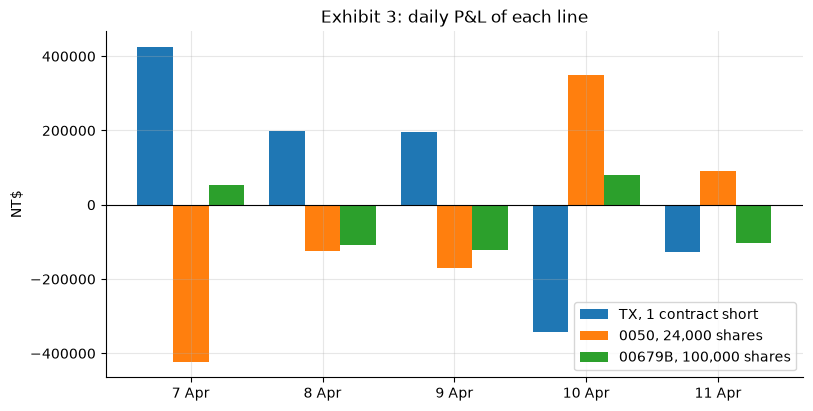

daily book P&L, Y h: [  57400.  -33000.  -95200.   87800. -141200.]


In [5]:
# simple returns combine with weights, log returns do not: a 60/40 mix of 0050 and 00679B on 7 April
w = np.array([0.0, 0.6, 0.4])
Rp = w @ R[0]
print(f"w'R = {Rp:.4%};  its log return ln(1 + w'R) = {math.log1p(Rp):.4%};  but w'r = {w @ np.log1p(R[0]):.4%}")

# Exhibit 3: each line's daily P&L for the fixed book
LINES = H * dP
days = ["7 Apr", "8 Apr", "9 Apr", "10 Apr", "11 Apr"]
fig, ax = plt.subplots()
for k, (nm, lab) in enumerate(zip(NAMES, ("TX, 1 contract short", "0050, 24,000 shares", "00679B, 100,000 shares"))):
    ax.bar(np.arange(5) + (k - 1) * 0.27, LINES[:, k], width=0.27, label=lab)
ax.axhline(0, color="black", lw=0.8); ax.set_xticks(range(5), days); ax.set_ylabel("NT$")
ax.set_title("Exhibit 3: daily P&L of each line"); ax.legend(); plt.show()
print("daily book P&L, Y h:", (dP @ H).round(2))

## Part 3 — Net and gross exposure, norms and distances (Example 4, Exhibit 4)

net exposure 1'f = 0.29528   gross exposure ||f||_1 = 1.14712
in NT$: net 2,952,800, gross 11,471,200
(f_TX, f_0050) = [-0.426  0.422]: Euclidean norm 0.600, 1-norm 0.848, net -0.004
distance between (0.6, 0.4) and (0.5, 0.5): 0.1414


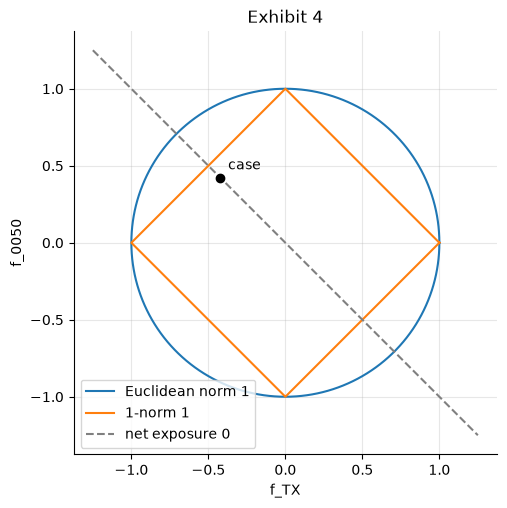

In [6]:
print(f"net exposure 1'f = {f.sum():.5f}   gross exposure ||f||_1 = {np.abs(f).sum():.5f}")
print(f"in NT$: net {W0 * f.sum():,.0f}, gross {W0 * np.abs(f).sum():,.0f}")
feq = f[:2]                                    # the equity lines (TX, 0050)
print(f"(f_TX, f_0050) = {feq.round(3)}: Euclidean norm {np.linalg.norm(feq):.3f}, 1-norm {np.abs(feq).sum():.3f}, net {feq.sum():.3f}")
print("distance between (0.6, 0.4) and (0.5, 0.5):", round(float(np.linalg.norm(np.array([0.6, 0.4]) - np.array([0.5, 0.5]))), 4))

th = np.linspace(0, 2 * np.pi, 361)
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot(np.cos(th), np.sin(th), label="Euclidean norm 1")
ax.plot([1, 0, -1, 0, 1], [0, 1, 0, -1, 0], label="1-norm 1")
ax.plot([-1.25, 1.25], [1.25, -1.25], "--", color="grey", label="net exposure 0")
ax.plot(*feq, "ko"); ax.annotate("case", feq, textcoords="offset points", xytext=(6, 6))
ax.set_aspect("equal"); ax.set_xlabel("f_TX"); ax.set_ylabel("f_0050"); ax.set_title("Exhibit 4"); ax.legend(loc="lower left"); plt.show()

## Part 4 — Cauchy–Schwarz, projections and angles on data columns

The inequality $\lvert\mathbf x^{\top}\mathbf y\rvert\le\lVert\mathbf x\rVert\lVert\mathbf y\rVert$ (8.6) is checked on real columns, not on random numbers: the week's return columns of the three instruments. The proof's $a^*=\mathbf x^{\top}\mathbf y/\lVert\mathbf y\rVert^2$ leaves a remainder $\mathbf x-a^*\mathbf y$ orthogonal to $\mathbf y$ (Exhibit 5).

In [7]:
def cos(x, y):
    return float(x @ y / (np.linalg.norm(x) * np.linalg.norm(y)))

for i, j in ((0, 1), (1, 2), (0, 2)):
    x, y = R[:, i], R[:, j]
    a = x @ y / (y @ y)
    print(f"{NAMES[i]:>6} / {NAMES[j]:<6} |x'y| = {abs(x @ y):.6f} <= {np.linalg.norm(x) * np.linalg.norm(y):.6f};"
          f"  a* = {a:+.4f}, x - a*y orthogonal to y: {abs((x - a * y) @ y) < 1e-12};"
          f"  uncentred angle {math.degrees(math.acos(cos(x, y))):.2f} deg")
# Example 5 and the picture of Exhibit 5
for x, y in ((np.array([0.6, 0.4]), np.array([0.5, 0.5])), (feq, np.ones(2)), (np.array([1.5, 2.5]), np.array([3.0, 1.0]))):
    print(f"x = {x}, y = {y}: cos = {cos(x, y):.5f}, angle = {math.degrees(math.acos(cos(x, y))):.2f} deg, a* = {x @ y / (y @ y):.4f}")

    TX / 0050   |x'y| = 0.024959 <= 0.025192;  a* = +1.0536, x - a*y orthogonal to y: True;  uncentred angle 7.80 deg
  0050 / 00679B |x'y| = 0.003335 <= 0.011383;  a* = +0.6097, x - a*y orthogonal to y: True;  uncentred angle 72.96 deg
    TX / 00679B |x'y| = 0.004006 <= 0.012105;  a* = +0.7325, x - a*y orthogonal to y: True;  uncentred angle 70.67 deg
x = [0.6 0.4], y = [0.5 0.5]: cos = 0.98058, angle = 11.31 deg, a* = 1.0000
x = [-0.42592  0.4224 ], y = [1. 1.]: cos = -0.00415, angle = 90.24 deg, a* = -0.0018
x = [1.5 2.5], y = [3. 1.]: cos = 0.75926, angle = 40.60 deg, a* = 0.7000


## Part 5 — Correlation as a cosine

**The week by hand (Example 6).** Centre each column, then take the cosine (8.9). The divisor cancels: `np.corrcoef`, `np.cov` with `ddof=0` or `ddof=1`, and the cosine of the centred vectors all give the same number.

In [8]:
x, y = 100 * R[:, 1], 100 * R[:, 2]            # 0050 and 00679B, in percent
# by hand, as the module prints it: inputs to 4 decimals, means to 5, centred values and products to 4
xh, yh = x.round(4), y.round(4)
xb, yb = round(xh.mean(), 5), round(yh.mean(), 5)
xch, ych = (xh - xb).round(4), (yh - yb).round(4)
prh = (xch * ych).round(4)
print("means:", xb, yb)
print(pl.DataFrame({"date": days, "x": xh, "y": yh, "x~": xch, "y~": ych, "x~ y~": prh}))
rho_h = 25.989 / math.sqrt(230.775 * 45.851)     # from the printed sums, as Example 6 does
print(f"sum x~y~ = {prh.sum():.4f}; |x~|^2 = {xch @ xch:.3f}; |y~|^2 = {ych @ ych:.3f}; "
      f"rho = {rho_h:.4f}, angle {math.degrees(math.acos(round(rho_h, 4))):.1f} deg; "
      f"uncentred {xh @ yh:.3f} / sqrt({xh @ xh:.3f} x {yh @ yh:.3f})")
# the same from the unrounded returns
xc, yc = x - x.mean(), y - y.mean()
rho_w = cos(xc, yc)
print(f"unrounded: cosine of the centred vectors {rho_w:.4f} (angle {math.degrees(math.acos(rho_w)):.2f} deg); uncentred {cos(x, y):.4f}")
for ddof in (0, 1):
    S = np.cov(x, y, ddof=ddof)
    print(f"ddof={ddof}: cov / (s_x s_y) = {S[0, 1] / math.sqrt(S[0, 0] * S[1, 1]):.4f}")
print("np.corrcoef:", round(float(np.corrcoef(x, y)[0, 1]), 4))

means: -1.10664 -1.32998
shape: (5, 6)
┌────────┬────────────┬───────────┬───────────┬───────────┬────────────┐
│ date   ┆ x          ┆ y         ┆ x~        ┆ y~        ┆ x~ y~      │
│ ---    ┆ ---        ┆ ---       ┆ ---       ┆ ---       ┆ ---        │
│ str    ┆ f64        ┆ f64       ┆ f64       ┆ f64       ┆ f64        │
╞════════╪════════════╪═══════════╪═══════════╪═══════════╪════════════╡
│ 7 Apr  ┆ -10.000000 ┆ 1.807200  ┆ -8.893400 ┆ 3.137200  ┆ -27.900400 │
│ 8 Apr  ┆ -3.251300  ┆ -3.583200 ┆ -2.144700 ┆ -2.253200 ┆ 4.832400   │
│ 9 Apr  ┆ -4.600300  ┆ -4.193700 ┆ -3.493700 ┆ -2.863700 ┆ 10.004900  │
│ 10 Apr ┆ 9.986300   ┆ 2.882600  ┆ 11.092900 ┆ 4.212600  ┆ 46.730000  │
│ 11 Apr ┆ 2.332100   ┆ -3.562800 ┆ 3.438700  ┆ -2.232800 ┆ -7.677900  │
└────────┴────────────┴───────────┴───────────┴───────────┴────────────┘
sum x~y~ = 25.9890; |x~|^2 = 230.775; |y~|^2 = 45.851; rho = 0.2527, angle 75.4 deg; uncentred 33.348 / sqrt(236.899 x 54.695)
unrounded: cosine of the centre

**The ETF frames.** The pairs of 0050 with 00631L and with 00679B use total returns, rebuilt as the LM1 and LM7 labs do. Each fund's total-return index runs on its own dates, $G_t=(P_t+D_t)/(P_{t-1}/s_t)$, with the cash dividend $D_t$ of every row of the dividend file and the split ratio $s_t$ (4 for 0050 on 2025-06-18, 22 for 00631L on 2026-03-31, 1 otherwise). The two indices are joined on their common dates, and returns run between consecutive common dates: 0050 was halted 11–17 June 2025 and 00631L 25–30 March 2026, so a return across a halt spans several sessions. Every close is first checked against FinMind's `spread`; the only mismatches allowed are ex-dividend and split days.

In [9]:
SPLITS = {"0050": ("2025-06-18", 4.0), "00631L": ("2026-03-31", 22.0)}

def tr_index(sym):
    raw = pl.read_csv(DATA / f"{sym}_daily_raw.csv").sort("date")
    dfile = DATA / f"{sym}_dividends.csv"
    div = (pl.read_csv(dfile).select("date", pl.col("cash_dividend").alias("D")) if dfile.exists()
           else pl.DataFrame({"date": [], "D": []}, schema={"date": pl.Utf8, "D": pl.Float64}))
    sdate, k = SPLITS.get(sym, ("", 1.0))
    gap = (pl.col("close") - pl.col("close").shift(1) - pl.col("spread")).abs()
    bad = set(raw.with_columns(gap.alias("gap")).filter(pl.col("gap") > 0.005)["date"])
    assert bad <= set(div["date"]) | {sdate}, sorted(bad - set(div["date"]))
    return (raw.join(div, on="date", how="left").sort("date")
               .with_columns(pl.col("D").fill_null(0.0),
                             pl.when(pl.col("date") == pl.lit(sdate)).then(pl.lit(k)).otherwise(pl.lit(1.0)).alias("s"))
               .with_columns(((pl.col("close") + pl.col("D")) / (pl.col("close").shift(1) / pl.col("s"))).fill_null(1.0).alias("G"))
               .select("date", pl.col("G").cum_prod().alias(f"I_{sym}")))

def pair(a, b, base=None):
    j = tr_index(a).join(tr_index(b), on="date", how="inner").sort("date")
    if base:
        j = j.filter(pl.col("date") >= pl.lit(base))
    return (j.with_columns((pl.col(f"I_{a}") / pl.col(f"I_{a}").shift(1) - 1).alias(f"R_{a}"),
                           (pl.col(f"I_{b}") / pl.col(f"I_{b}").shift(1) - 1).alias(f"R_{b}"))
             .drop_nulls(f"R_{a}"))

lm1 = pair("0050", "00631L")                    # LM1's frame
lm7 = pair("0050", "00679B", base="2017-01-17")  # LM7's frame
for name, fr, b in (("LM1", lm1, "00631L"), ("LM7", lm7, "00679B")):
    r = np.corrcoef(fr["R_0050"].to_numpy(), fr[f"R_{b}"].to_numpy())[0, 1]
    print(f"{name}: T = {fr.height}, {fr['date'][0]} .. {fr['date'][-1]}, rho(0050, {b}) = {r:.6f}, angle {math.degrees(math.acos(r)):.3f} deg")
assert lm1.height == 2902 and lm7.height == 2363

LM1: T = 2902, 2014-11-03 .. 2026-10-08, rho(0050, 00631L) = 0.974365, angle 13.001 deg
LM7: T = 2363, 2017-01-18 .. 2026-10-08, rho(0050, 00679B) = -0.105632, angle 96.064 deg


A = 243.0543; vols 20.106% and 13.496%; rho -0.1056, angle 96.06 deg
42.3/57.7 mix, rebalanced daily: 10.908% against the bound 16.292%
check from the printed inputs: 10.908 %


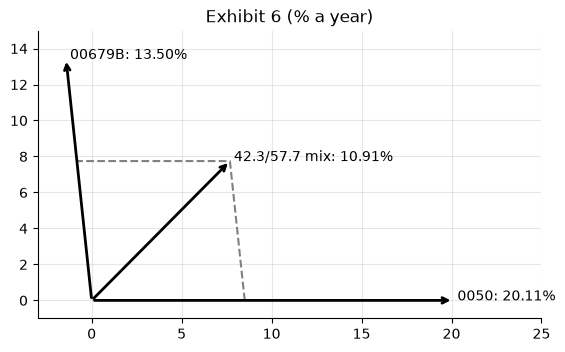

In [10]:
# Exhibit 6 and Example 7: 0050 and 00679B in their own plane, LM7's sample
a7, b7 = lm7["R_0050"].to_numpy(), lm7["R_00679B"].to_numpy()
T7 = len(a7)
A7 = T7 / ((date(2026, 10, 8) - date(2017, 1, 17)).days / 365.25)
s1, s2, r7 = a7.std() * math.sqrt(A7), b7.std() * math.sqrt(A7), np.corrcoef(a7, b7)[0, 1]
mix = 0.423 * a7 + 0.577 * b7
print(f"A = {A7:.4f}; vols {s1:.3%} and {s2:.3%}; rho {r7:.4f}, angle {math.degrees(math.acos(r7)):.2f} deg")
print(f"42.3/57.7 mix, rebalanced daily: {mix.std() * math.sqrt(A7):.3%} against the bound {0.423 * s1 + 0.577 * s2:.3%}")
print("check from the printed inputs:", round(math.sqrt(0.423**2 * 20.106**2 + 0.577**2 * 13.496**2
      + 2 * 0.423 * 0.577 * -0.1056 * 20.106 * 13.496), 3), "%")
th7 = math.acos(r7)
v1, v2 = np.array([100 * s1, 0.0]), 100 * s2 * np.array([math.cos(th7), math.sin(th7)])
vm = 0.423 * v1 + 0.577 * v2
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for v, lab in ((v1, "0050"), (v2, "00679B"), (vm, "42.3/57.7 mix")):
    ax.annotate("", v, (0, 0), arrowprops={"arrowstyle": "->", "lw": 2}); ax.text(*v, f" {lab}: {np.linalg.norm(v):.2f}%")
ax.plot([0.423 * v1[0], vm[0], 0.577 * v2[0]], [0.423 * v1[1], vm[1], 0.577 * v2[1]], "--", color="grey")
ax.set_xlim(-3, 25); ax.set_ylim(-1, 15); ax.set_aspect("equal"); ax.set_title("Exhibit 6 (% a year)"); plt.show()

**The sector sample, with its repair.** FinMind serves some sector closes copied from another date or from another series on the same date (Getting Started, "Check, do not trust"). `sectors_close_repairs.csv` lists every close the book repairs, with the official 13:30:00 value in `close_1330`. **Rule:** replace each listed close with `close_1330`; if `close_1330` is empty, drop that close. On FinMind's free plan `close_1330` is empty, because the 13:30:00 values come from a paid dataset, so every listed close is dropped. Returns stay between consecutive TAIEX-calendar dates, so a dropped close removes the returns into and out of its date.

**U28** is the 28 leaf indices among the 30 TWSE sector indices that FinMind serves daily: all except the aggregates `Electronic` and `ChemicalBiotechnologyMedicalCare`, on one common sample of daily price returns from 2008-12-01. TWSE compiles them as price indices (IndexS03), so their returns leave out cash dividends.

In [11]:
raw = pl.read_csv(DATA / "sectors_close_raw.csv", infer_schema_length=None)
rep = pl.read_csv(DATA / "sectors_close_repairs.csv", infer_schema_length=None,
                  schema_overrides={"close_1330": pl.Float64})
ids = [c for c in raw.columns if c != "date"]
long = raw.unpivot(index="date", on=ids, variable_name="id", value_name="close")
fixed = (long.join(rep.with_columns(pl.lit(True).alias("listed")), on=["id", "date"], how="left")
             .with_columns(pl.when(pl.col("listed").fill_null(False)).then(pl.col("close_1330"))
                           .otherwise(pl.col("close")).alias("close")))
closes = fixed.pivot(on="id", index="date", values="close").sort("date").select("date", *ids)
replaced = rep.filter(pl.col("close_1330").is_not_null()).height
dropped = rep.height - replaced
AGG = ["Electronic", "ChemicalBiotechnologyMedicalCare"]
U28 = [c for c in ids if c not in ("TAIEX", *AGG)]
in_smp = rep.filter(pl.col("id").is_in(U28) & (pl.col("date") >= pl.lit("2008-12-01")))
print(f"rule: replace each listed close with its 13:30:00 value, drop it if that value is missing")
print(f"listed closes: {rep.height}; replaced {replaced}, dropped {dropped}; in the U28 sample: {in_smp.height} closes on {in_smp['date'].n_unique()} dates")

smp = closes.filter(pl.col("date") >= pl.lit("2008-12-01")).sort("date")
ret28 = (smp.select("date", *[(pl.col(c) / pl.col(c).shift(1) - 1).alias(c) for c in U28])
            .slice(1).drop_nulls())
X28 = ret28.select(U28).to_numpy()
T28 = X28.shape[0]
print(f"U28: {len(U28)} indices, T = {T28} returns, {ret28['date'][0]} .. {ret28['date'][-1]}")
assert T28 == (4382 if dropped == 0 else 4307), T28

rule: replace each listed close with its 13:30:00 value, drop it if that value is missing
listed closes: 561; replaced 561, dropped 0; in the U28 sample: 524 closes on 38 dates
U28: 28 indices, T = 4382 returns, 2008-12-02 .. 2026-10-08


On a paid plan every listed close is replaced and $T=4{,}382$; on the free plan the 561 listed closes are dropped and $T=4{,}307$. **What changes on the free plan:** every number computed from U28 below, that is the four sector pairs of Exhibit 7, the largest and smallest of the 378 correlations, the identity check (8.10) and the S3 bound (8.11). The ETF pairs and everything about the case week do not change.

In [12]:
C28 = np.corrcoef(X28, rowvar=False)
iu = np.triu_indices(len(U28), 1)
vals = C28[iu]
kmax, kmin = int(np.argmax(vals)), int(np.argmin(vals))
print(f"{len(vals)} pairs; largest {U28[iu[0][kmax]]} / {U28[iu[1][kmax]]} {vals[kmax]:.4f}; "
      f"smallest {U28[iu[0][kmin]]} / {U28[iu[1][kmin]]} {vals[kmin]:.4f}; median {np.median(vals):.4f}")
ix = {n: i for i, n in enumerate(U28)}
PAIRS = [("0050/00631L", lm1["R_0050"].to_numpy(), lm1["R_00631L"].to_numpy()),
         ("Parts/Computer", X28[:, ix["ElectronicPartsComponents"]], X28[:, ix["ComputerPeripheralEquipment"]]),
         ("Semi/Financial", X28[:, ix["Semiconductor"]], X28[:, ix["FinancialInsurance"]]),
         ("Semi/Food", X28[:, ix["Semiconductor"]], X28[:, ix["Food"]]),
         ("Biotech/OilGas", X28[:, ix["BiotechnologyMedicalCare"]], X28[:, ix["OilGasElectricity"]]),
         ("0050/00679B", a7, b7)]
rows = []
for lab, x, y in PAIRS:
    c = cos(x - x.mean(), y - y.mean())
    rows.append({"pair": lab, "T": len(x), "cosine of centred": c, "np.corrcoef": float(np.corrcoef(x, y)[0, 1]),
                 "angle (deg)": math.degrees(math.acos(c)), "uncentred cosine": cos(x, y)})
ang = pl.DataFrame(rows)
ang   # Exhibit 7

378 pairs; largest ComputerPeripheralEquipment / ElectronicPartsComponents 0.7547; smallest BiotechnologyMedicalCare / OilGasElectricity 0.2175; median 0.5015


pair,T,cosine of centred,np.corrcoef,angle (deg),uncentred cosine
str,i64,f64,f64,f64,f64
"""0050/00631L""",2902,0.974365,0.974365,13.001337,0.974478
"""Parts/Computer""",4382,0.754715,0.754715,40.999509,0.755274
"""Semi/Financial""",4382,0.574858,0.574858,54.910279,0.575796
"""Semi/Food""",4382,0.403495,0.403495,66.203143,0.404578
"""Biotech/OilGas""",4382,0.217481,0.217481,77.438867,0.217704
"""0050/00679B""",2363,-0.105632,-0.105632,96.063569,-0.105699


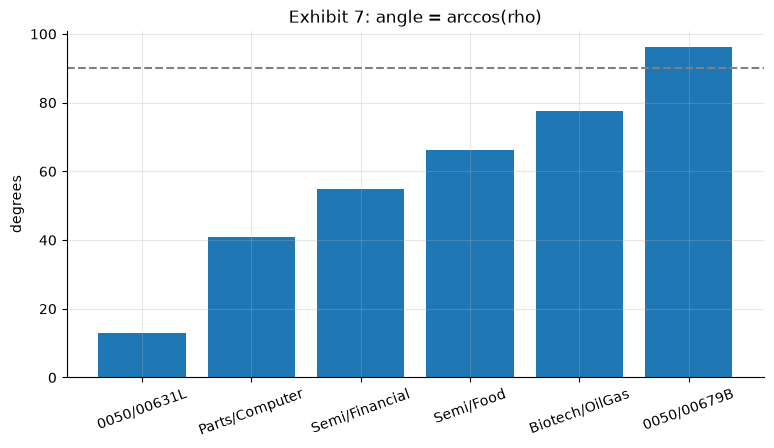

|zx|^2 = 4382.00 = T; squared distance 3725.94 = 2T(1 - rho) 3725.94
S3 equal weights: s_p = 1.0527% a day <= sum w_i s_i = 1.2721%


In [13]:
fig, ax = plt.subplots()
ax.bar(ang["pair"].to_list(), ang["angle (deg)"].to_numpy())
ax.axhline(90, ls="--", color="grey"); ax.set_ylabel("degrees"); ax.set_title("Exhibit 7: angle = arccos(rho)")
plt.xticks(rotation=20); plt.show()

# (8.10): standardized vectors have length sqrt(T); their squared distance is 2T(1 - rho)
x, y = X28[:, ix["Semiconductor"]], X28[:, ix["FinancialInsurance"]]
zx, zy = (x - x.mean()) / x.std(), (y - y.mean()) / y.std()
rho_sf = np.corrcoef(x, y)[0, 1]
print(f"|zx|^2 = {zx @ zx:.2f} = T; squared distance {np.sum((zx - zy)**2):.2f} = 2T(1 - rho) {2 * T28 * (1 - rho_sf):.2f}")
# (8.11): the equal-weight mix of S3, rebalanced daily
S3 = X28[:, [ix[n] for n in ("Semiconductor", "FinancialInsurance", "Food")]]
print(f"S3 equal weights: s_p = {S3.mean(axis=1).std():.4%} a day <= sum w_i s_i = {S3.std(axis=0).mean():.4%}")

In [14]:
# price returns against total returns: 0050 / 00679B on their own common dates, 0050's split day excluded
cal = raw["date"].to_list()                      # the TAIEX calendar

def price_returns(sym, skip=None):
    c = dict(pl.read_csv(DATA / f"{sym}_daily_raw.csv").select("date", "close").iter_rows())
    return {cal[i]: c[cal[i]] / c[cal[i - 1]] - 1 for i in range(1, len(cal))
            if cal[i] in c and cal[i - 1] in c and cal[i] != skip}

pr50, pr679 = price_returns("0050", skip="2025-06-18"), price_returns("00679B")
com = sorted(set(pr50) & set(pr679))
print(f"price returns: T = {len(com)}, rho = {np.corrcoef([pr50[d] for d in com], [pr679[d] for d in com])[0, 1]:.4f}; "
      f"total returns (LM7): rho = {r7:.4f}")

price returns: T = 2362, rho = -0.1050; total returns (LM7): rho = -0.1056


## Part 6 — The data matrix: $X$, $Y$, $X\mathbf w$, $Y\mathbf h$ (Exhibit 8, Example 8)

Row $t$ of $X$ is $\mathbf R_t^{\top}$ (date first, asset second); row $t$ of $Y$ is $\Delta\mathbf P_t^{\top}$. $X\mathbf w$ is the return series of a portfolio rebalanced to $\mathbf w$ at every close; $Y\mathbf h$ is the P&L of a book that never trades. A fixed book's exposures drift as prices move.

X: (5, 3)  Y: (5, 3)  X^T: (3, 5)


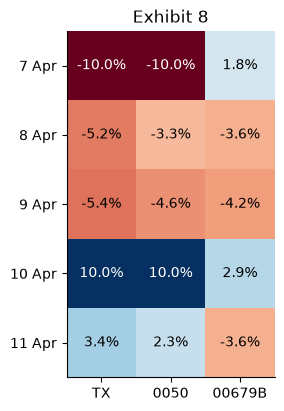

Example 8 X w (%): [-5.277 -3.384 -4.438  7.145 -0.026]  sum -5.98%, compounded -6.32%
by columns: True
Y h (NT$): [  57400.  -33000.  -95200.   87800. -141200.]  1'Y h = -124200.0  = h'(P_11 - P_2) = -124200.0
equity at the close of 7 April: 10,057,400
exposures at the close of 2 April: [-0.426  0.422  0.299]   at the close of 7 April: [-0.381  0.378  0.302]
8 April: the fixed book returned -0.328%; the 2 April exposures give -0.226%; today's exposures give -0.328%


In [15]:
X, Y = R, dP                                   # 5 x 3 each
print("X:", X.shape, " Y:", Y.shape, " X^T:", X.T.shape)
fig, ax = plt.subplots(figsize=(4.5, 4.5))
im = ax.imshow(X, cmap="RdBu", vmin=-0.1, vmax=0.1)
ax.set_xticks(range(3), NAMES); ax.set_yticks(range(5), days)
for (i, j), v in np.ndenumerate(X):
    ax.text(j, i, f"{v:.1%}", ha="center", va="center", color="white" if abs(v) > 0.06 else "black")
ax.grid(False); ax.set_title("Exhibit 8"); plt.show()

w = np.array([0.0, 0.6, 0.4])
Xw = X @ w
print("Example 8 X w (%):", (100 * Xw).round(3), f" sum {Xw.sum():.2%}, compounded {np.prod(1 + Xw) - 1:.2%}")
print("by columns:", np.allclose(Xw, 0.6 * X[:, 1] + 0.4 * X[:, 2]))
print("Y h (NT$):", (Y @ H).round(2), " 1'Y h =", round(float(np.ones(5) @ Y @ H), 2),
      " = h'(P_11 - P_2) =", round(float(H @ (P[-1] - P[0])), 2))

# the drift: exposures of the fixed book after 7 April, and the 8 April return
W7 = W0 + H @ dP[0]                            # equity at the close of 7 April: W0 plus that day's P&L
f7 = H * P[1] / W7
print(f"equity at the close of 7 April: {W7:,.0f}")
print("exposures at the close of 2 April:", f.round(3), "  at the close of 7 April:", f7.round(3))
print(f"8 April: the fixed book returned {(H @ dP[1]) / W7:.3%}; the 2 April exposures give {f @ R[1]:.3%}; "
      f"today's exposures give {f7 @ R[1]:.3%}")

## Part 7 — Matrix products (Exhibit 9, Example 9)

The columns of $K$ are the weights of three portfolios: 100% 0050, 60/40 and 50/50 in 0050 and 00679B. Each column of $XK$ is one portfolio's return series.

In [16]:
K = np.array([[0, 0, 0], [1, 0.6, 0.5], [0, 0.4, 0.5]])
XK = X @ K
xk = pl.DataFrame({"session": days, "100% 0050": 100 * XK[:, 0], "60/40": 100 * XK[:, 1], "50/50": 100 * XK[:, 2]})
print(xk)
print("sum of daily returns (%):", (100 * XK.sum(axis=0)).round(3))
print("compounded week (%):    ", (100 * (np.prod(1 + XK, axis=0) - 1)).round(3))   # Exhibit 9

prop = np.array([0.2, 0.3, 0.5])               # holding the three portfolios in these proportions
print("associative:", np.allclose((X @ K) @ prop, X @ (K @ prop)), " combined weights K prop =", K @ prop)
print("(XK)^T = K^T X^T:", np.allclose((X @ K).T, K.T @ X.T), "  X I = X:", np.allclose(X @ np.eye(3), X))
M1, M2 = np.array([[1, 1], [0, 1]]), np.array([[1, 0], [1, 1]])
print("M1 M2 =", (M1 @ M2).tolist(), " M2 M1 =", (M2 @ M1).tolist())
print("1-D arrays have no orientation:", w.shape, w.T.shape, "  an explicit column:", w.reshape(-1, 1).shape)

shape: (5, 4)
┌─────────┬────────────┬───────────┬───────────┐
│ session ┆ 100% 0050  ┆ 60/40     ┆ 50/50     │
│ ---     ┆ ---        ┆ ---       ┆ ---       │
│ str     ┆ f64        ┆ f64       ┆ f64       │
╞═════════╪════════════╪═══════════╪═══════════╡
│ 7 Apr   ┆ -10.000000 ┆ -5.277108 ┆ -4.096386 │
│ 8 Apr   ┆ -3.251263  ┆ -3.384025 ┆ -3.417216 │
│ 9 Apr   ┆ -4.600326  ┆ -4.437659 ┆ -4.396992 │
│ 10 Apr  ┆ 9.986320   ┆ 7.144817  ┆ 6.434441  │
│ 11 Apr  ┆ 2.332090   ┆ -0.025859 ┆ -0.615346 │
└─────────┴────────────┴───────────┴───────────┘
sum of daily returns (%): [-5.533 -5.98  -6.091]
compounded week (%):     [-6.506 -6.319 -6.328]
associative: True  combined weights K prop = [0.   0.63 0.37]
(XK)^T = K^T X^T: True   X I = X: True
M1 M2 = [[2, 1], [1, 1]]  M2 M1 = [[1, 1], [1, 2]]
1-D arrays have no orientation: (3,) (3,)   an explicit column: (3, 1)


In [17]:
# Example 9: the week line by line, and the second trader's book
print("week, line by line (NT$):", (H * (P[-1] - P[0])).round(2), " total", round(float(H @ (P[-1] - P[0])), 2))
print("TX fell", f"{-(P[-1, 0] - P[0, 0]) / P[0, 0]:.1%}", "and 0050", f"{-(P[-1, 1] - P[0, 1]) / P[0, 1]:.1%}", "over the week")
print("second trader: 7 April", round(float(H_B @ dP[0]), 2), "; week", round(float(H_B @ (P[-1] - P[0])), 2))

week, line by line (NT$): [ 350600. -274800. -200000.]  total -124200.0
TX fell 8.2% and 0050 6.5% over the week
second trader: 7 April 127800.0 ; week -78400.0


## Part 8 — Practice-problem solutions (computational)

In [18]:
H2 = np.array([2, 0, 200_000])
print("PP2: 8 April P&L of (2, 0, 200,000):", round(float(H2 @ dP[1]), 2))
f2 = H2 * P[0] / W0
print(f"PP3: f = {f2}, net = gross = {f2.sum():.5f}; W0 f'R(7 Apr) = {W0 * f2 @ R[0]:,.2f} = h'dP {H2 @ dP[0]:,.2f}")
wa, wb = np.array([0.5, 0.3, 0.2]), np.array([0.4, 0.3, 0.3])
print(f"PP4: norms {np.linalg.norm(wa):.4f}, {np.linalg.norm(wb):.4f}; distance {np.linalg.norm(wb - wa):.4f}; "
      f"relative {np.linalg.norm(wb - wa) / np.linalg.norm(wa):.4f}; 1-norm {np.abs(wb - wa).sum():.1f} "
      f"(two-way turnover {np.abs(wb - wa).sum():.0%}, one way {np.abs(wb - wa).sum() / 2:.0%})")
x6, y6 = np.array([1.0, 2, 2]), np.array([2.0, 1, 2])
a6 = x6 @ y6 / (y6 @ y6)
print(f"PP6: angle {math.degrees(math.acos(cos(x6, y6))):.2f} deg; a = {a6:.4f} = 8/9; "
      f"x - a y orthogonal to y: {abs((x6 - a6 * y6) @ y6) < 1e-12}")
x7, y7 = np.array([2.0, 4, 0, 2]), np.array([1.0, 3, 1, 3])
for d in (0, 1):
    S7 = np.cov(x7, y7, ddof=d)
    print(f"PP7: divisor {4 - d}: covariance {S7[0, 1]:.4f}, rho {S7[0, 1] / math.sqrt(S7[0, 0] * S7[1, 1]):.4f}")
print(f"PP7: cosine of the centred vectors {cos(x7 - x7.mean(), y7 - y7.mean()):.4f}")
for r in (0.7547, 0.2175):
    print(f"PP9: rho {r}: angle {math.degrees(math.acos(r)):.2f} deg, sqrt(2(1 - rho)) = {math.sqrt(2 * (1 - r)):.4f}")
# PP10, option C: the daily P&Ls W0 X f with the exposures of 2 April against the fixed book's Y h
print("PP10: W0 X f (NT$):", (W0 * (X @ f)).round(2))
print("      Y h (NT$):    ", (Y @ H).round(2))
print("      miss, W0 X f - Y h:", (W0 * (X @ f) - Y @ H).round(2) + 0.0, "(exact on 7 April only)")   # + 0.0: no -0.
# PP11: Part 1 joined the files; the five returns as a Polars frame
wk = pl.DataFrame({"date": apr["date"][1:], "R_0050": R[:, 1], "R_00679B": R[:, 2]})
xa, ya = wk["R_0050"].to_numpy(), wk["R_00679B"].to_numpy()
print("PP11:", round(cos(xa - xa.mean(), ya - ya.mean()), 4), round(float(np.corrcoef(xa, ya)[0, 1]), 4))

PP2: 8 April P&L of (2, 0, 200,000): -617200.0
PP3: f = [0.85184 0.      0.5976 ], net = gross = 1.44944; W0 f'R(7 Apr) = -743,600.00 = h'dP -743,600.00
PP4: norms 0.6164, 0.5831; distance 0.1414; relative 0.2294; 1-norm 0.2 (two-way turnover 20%, one way 10%)
PP6: angle 27.27 deg; a = 0.8889 = 8/9; x - a y orthogonal to y: True
PP7: divisor 4: covariance 1.0000, rho 0.7071
PP7: divisor 3: covariance 1.3333, rho 0.7071
PP7: cosine of the centred vectors 0.7071
PP9: rho 0.7547: angle 41.00 deg, sqrt(2(1 - rho)) = 0.7004
PP9: rho 0.2175: angle 77.44 deg, sqrt(2(1 - rho)) = 1.2510
PP10: W0 X f (NT$): [  57400.    -22627.59  -88719.35   82132.27 -152385.38]
      Y h (NT$):     [  57400.  -33000.  -95200.   87800. -141200.]
      miss, W0 X f - Y h: [     0.    10372.41   6480.65  -5667.73 -11185.38] (exact on 7 April only)
PP11: 0.2526 0.2526


### Extension: how far is 00631L from twice 0050?

00631L is the daily 2× fund on 0050's index. If it delivered exactly twice 0050's daily return, the vector $\mathbf x_{00631L}-2\mathbf x_{0050}$ would be zero and the ratio of the lengths would be 2. The cell below measures both on LM1's frame. Then explore: compute the same per calendar year; compare centred and uncentred versions; and find the dates that contribute most to the gap. Which of them are halts or splits, where one return spans several sessions? What else, from Volume I, could make a 2× fund's daily return differ from twice its index's?

In [19]:
x50, x631 = lm1["R_0050"].to_numpy(), lm1["R_00631L"].to_numpy()
gap = x631 - 2 * x50
print(f"root-mean-square gap per day {math.sqrt(np.mean(gap**2)):.4%} (uncentred); "
      f"length ratio |x_00631L| / |x_0050| = {np.linalg.norm(x631) / np.linalg.norm(x50):.4f}")
print(f"centred: {math.sqrt(np.mean((gap - gap.mean())**2)):.4%}, "
      f"{np.linalg.norm(x631 - x631.mean()) / np.linalg.norm(x50 - x50.mean()):.4f}")
# your code: per-year gaps, the largest contributions to |gap|^2, and the dates of the two halts

root-mean-square gap per day 0.5577% (uncentred); length ratio |x_00631L| / |x_0050| = 1.9357
centred: 0.5575%, 1.9362
